# Exploratory Data Analysis (EDA): Bank Marketing

# 1 Introduction

A Portuguese bank called its clients by phone to sell a term deposit.
Each row is one client; the column `y` says if the client subscribed (yes) or not (no).
Goal: understand the data, fix data quality problems and find which client characteristics are related to a "yes".

# 2 Libraries and dataset

## 2.1 Import libraries

In [1]:
# import libraries
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

from scipy import stats

## 2.2 Load data

In [2]:
# load data
DATA_PATH = Path("../data/bank-full.csv")
df = pd.read_csv(DATA_PATH, sep=";")

print("Rows and columns:", df.shape)
df.head()

Rows and columns: (45211, 17)


,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,no
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,no
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown,no
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,unknown,no


# 3 Data exploration

## 3.1 Data loading and integrity check

**Observations**
- No empty cells and no duplicate rows.
- "unknown" is a missing value in disguise: `poutcome` 81.7%, `contact` 28.8%, `education` 4.1%, `job` 0.6%.
- `default`, `housing`, `loan` and `y` have only two values (yes/no).
- `day` is stored as a number, but it is a day of the month.

In [29]:
# Let's check that the data has been loaded correctly.
print("Duplicate rows:", df.duplicated().sum())
integrity = pd.DataFrame({
    "type": df.dtypes.astype(str),
    "empty_cells": df.isna().sum(),
    "unknown_values": (df == "unknown").sum(),
    "distinct_values": df.nunique(),
})
integrity["unknown_values_%"] = (integrity["unknown_values"] / len(df) * 100).round(1)
integrity

Duplicate rows: 0


,type,empty_cells,unknown_values,distinct_values,unknown_values_%
age,int64,0,0,77,0.0
job,str,0,288,12,0.6
marital,str,0,0,3,0.0
education,str,0,1857,4,4.1
default,str,0,0,2,0.0
balance,int64,0,0,7168,0.0
housing,str,0,0,2,0.0
loan,str,0,0,2,0.0
contact,str,0,13020,3,28.8
day,int64,0,0,31,0.0


### 3.1.1 Data dictionary

Source: `bank-names.txt`. One row = one client contacted by phone.
45,211 rows, 17 columns, no empty cells.

| # | Column | Meaning | Type | Values / range | Notes |
|---|---|---|---|---|---|
| 1 | `age` | Age of the client | Numeric | 18 – 95 | Median 39 |
| 2 | `job` | Type of job | Categorical | 12 values | 288 "unknown" |
| 3 | `marital` | Marital status | Categorical | married, single, divorced | "divorced" also means widowed |
| 4 | `education` | Education level | Categorical | primary, secondary, tertiary, unknown | 1,857 "unknown" |
| 5 | `default` | Has credit in default? | Binary | yes / no | 98% "no": little information |
| 6 | `balance` | Average yearly balance (EUR) | Numeric | −8,019 – 102,127 | Median 448: very skewed |
| 7 | `housing` | Has a housing loan? | Binary | yes / no | |
| 8 | `loan` | Has a personal loan? | Binary | yes / no | |
| 9 | `contact` | How the client was contacted | Categorical | cellular, telephone, unknown | 13,020 "unknown" |
| 10 | `day` | Day of the month of the last contact | Numeric | 1 – 31 | A calendar day, not a quantity |
| 11 | `month` | Month of the last contact | Categorical | jan – dec | No year in the data |
| 12 | `duration` | Length of the last call (seconds) | Numeric | 0 – 4,918 | Known only after the call: leakage, removed |
| 13 | `campaign` | Calls to this client in this campaign | Numeric | 1 – 63 | Median 2 |
| 14 | `pdays` | Days since the last contact in a previous campaign | Numeric | −1 – 871 | −1 = never contacted before |
| 15 | `previous` | Calls to this client before this campaign | Numeric | 0 – 275 | 275 looks like an error |
| 16 | `poutcome` | Result of the previous campaign | Categorical | success, failure, other, unknown | 36,959 "unknown" |
| 17 | `y` | **Target**: did the client subscribe a term deposit? | Binary | yes / no | 11.7% yes: unbalanced |

### 3.1.2 Data quality checks

**Data quality**
- `pdays` = -1 for 36954 (81.7%). It means "never contacted before".
- One row was removed where `previous = 275` because it is probably an error, as this value is too high compared to the average."
- `duration` is known only after the call. I will not use it to predict. This is data leakage.
- The classes are unbalanced because only 11.7% of the clients said 'yes'.

In [4]:
never_contacted = (df["pdays"] == -1).sum()
print("pdays = -1:", never_contacted, f"({never_contacted / len(df) * 100:.1f}%)")

highest_previous = df["previous"].sort_values(ascending=False).head(5)
print("Highest 'previous':", highest_previous.tolist())

print(df.groupby("y")["duration"].median())

print("\nTarget:")
print(df["y"].value_counts(normalize=True).round(3))

pdays = -1: 36954 (81.7%)
Highest 'previous': [275, 58, 55, 51, 41]
y
no     164.0
yes    426.0
Name: duration, dtype: float64

Target:
y
no     0.883
yes    0.117
Name: proportion, dtype: float64


## 3.2 Data cleaning

**Cleaning decisions**
- There are many unknown rows, and deleting them would remove too much data.
- A new column `contacted_before` was created because pdays uses the value -1 as a special code for `never contacted before`.
- One row was removed where `previous = 275` because it is probably an error, as this value is too high compared to the average."
- `duration` was removed because it is strongly related to the answer, but it is known only after the call (data leakage).
- `y` converted to True/False.

In [5]:
clean = df.copy()

clean["contacted_before"] = clean["pdays"] != -1
clean = clean[clean["previous"] != 275]
clean["y"] = clean["y"] == "yes"
clean = clean.drop(columns=["duration"])

display(len(df))
display(len(clean))

percentage = clean["y"].mean() * 100
print(f"Clients who said yes: {percentage:.1f}%")

45211

45210

Clients who said yes: 11.7%


## 3.3 Exploratory Data Analysis
Goals:
- Study the features: distributions, typical values, ranges.
- Find relations between feature and the target.
- Find potential problems for the model: skweness, rare categories.

### 3.3.1 Descriptive statistics and distributions

In [6]:
# Descriptive statistics of numeric features
clean.describe().T

,count,mean,std,min,25%,50%,75%,max
age,45210.0,40.936231,10.618879,18.0,33.0,39.0,48.0,95.0
balance,45210.0,1362.290179,3044.797065,-8019.0,72.0,448.0,1428.0,102127.0
day,45210.0,15.806724,8.322315,1.0,8.0,16.0,21.0,31.0
campaign,45210.0,2.763858,3.098053,1.0,1.0,2.0,3.0,63.0
pdays,45210.0,40.192922,100.124419,-1.0,-1.0,-1.0,-1.0,871.0
previous,45210.0,0.574253,1.907928,0.0,0.0,0.0,0.0,58.0


**Distribution of the target variable "y"**

y
False    39921
True      5289
Name: count, dtype: int64


Text(0, 0.5, 'Number of clients')

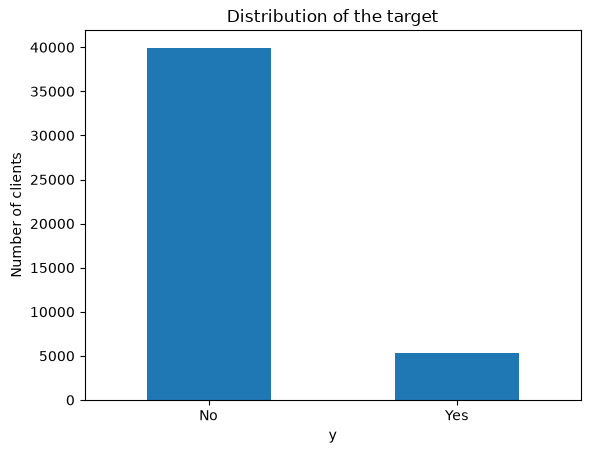

In [7]:
counts = clean["y"].value_counts()
print(counts)

ax = counts.plot(kind="bar", title="Distribution of the target")
ax.set_xticklabels(["No", "Yes"], rotation=0)
ax.set_ylabel("Number of clients")

**Distribution of the numeric features**. We check if there are any asymmetries (skewness) and outliers.
- `campaign`, `previous`, and `balance`have a very strong positive skewness (a long tail on the right).

**Outliers in the numeric features**: boxplots and the IQR rule
  (a value is an outlier if it is below Q1 − 1.5·IQR or above Q3 + 1.5·IQR).
- In `age`, we do not have real outliers, just rare values.
- In `balance`, we have outliers for both very wealthy clients and those with a negative balance, which seems normal for a bank.
- `campaign` 3,064 outliers, clients called more than 6 times (up to 63). Plausible values: kept.
- `previous` the IQR rule does not work here (Q1 = Q3 = 0), so every client contacted before counts as an outlier. Kept; summarised by contacted_before.



Text(0, 0.5, 'Number of clients')

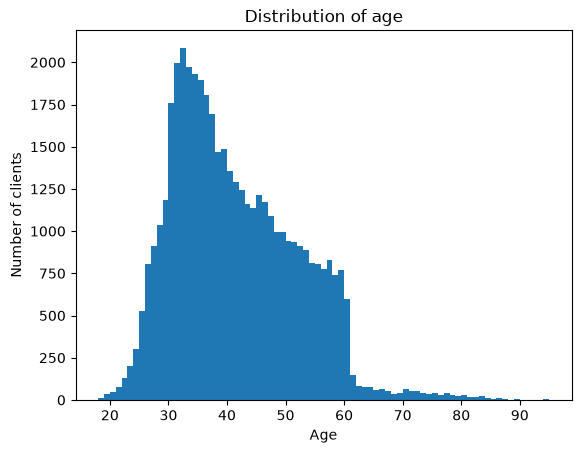

In [8]:
ax = clean["age"].plot(kind="hist", bins=range(18,96), title="Distribution of age")
ax.set_xlabel("Age")
ax.set_ylabel("Number of clients")

Text(0, 0.5, 'Number of clients')

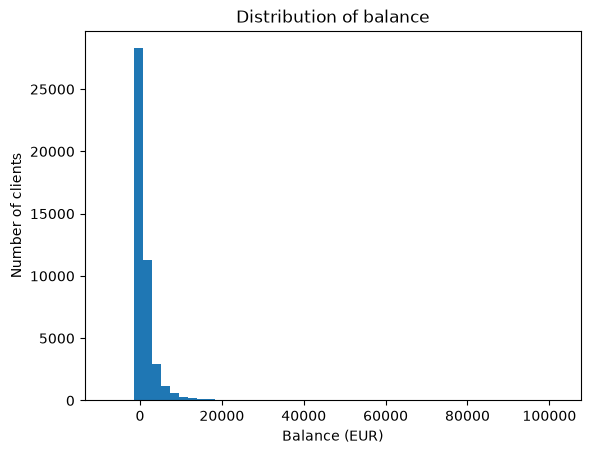

In [9]:
ax = clean["balance"].plot(kind="hist", bins=50, title="Distribution of balance")
ax.set_xlabel("Balance (EUR)")
ax.set_ylabel("Number of clients")

Text(0, 0.5, 'Number of clients')

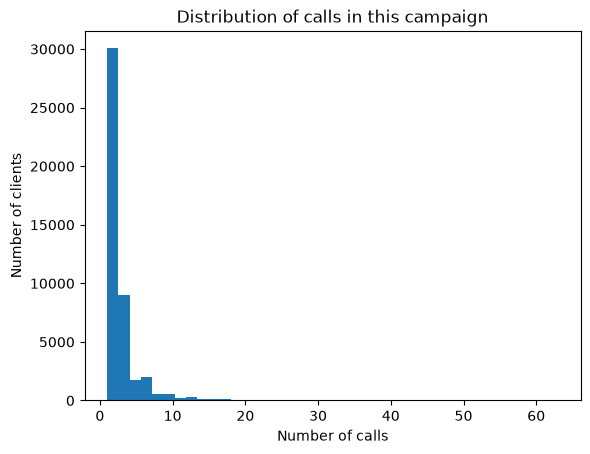

In [10]:
ax = clean["campaign"].plot(kind="hist", bins=40, title="Distribution of calls in this campaign")
ax.set_xlabel("Number of calls")
ax.set_ylabel("Number of clients")

In [11]:
# Skewness: 0 = symmetric, above 1 = strong tail on the right
clean[["age", "balance", "campaign", "previous"]].skew().round(1)

age         0.7
balance     8.4
campaign    4.9
previous    7.8
dtype: float64

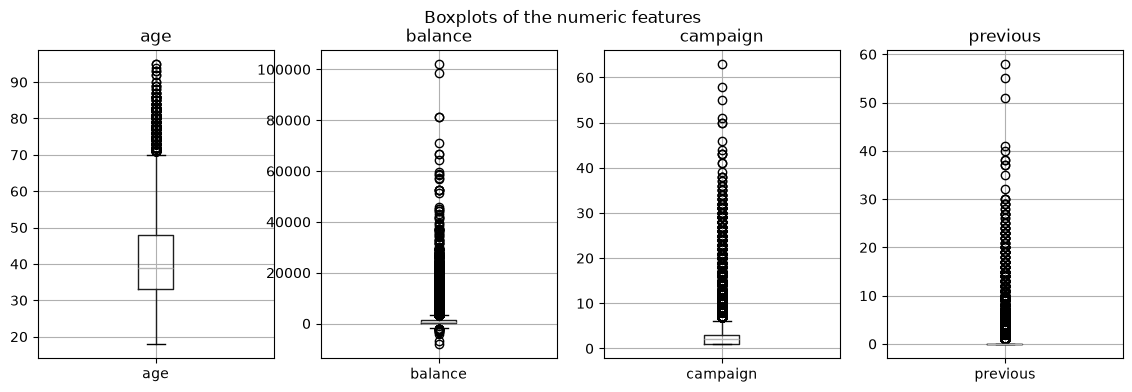

In [12]:
# Outliers in the numeric features
fig, axes = plt.subplots(1, 4, figsize=(14, 4))
for ax, column in zip(axes, ["age", "balance", "campaign", "previous"]):
    clean.boxplot(column=column, ax=ax)
    ax.set_title(column)
fig.suptitle("Boxplots of the numeric features")
plt.show()

In [13]:
columns = ["age", "balance", "campaign", "previous"]
q1 = clean[columns].quantile(0.25)
q3 = clean[columns].quantile(0.75)
iqr = q3 - q1
lower = q1 - 1.5 * iqr
upper = q3 + 1.5 * iqr
outliers = ((clean[columns] < lower) | (clean[columns] > upper)).sum()

pd.DataFrame({
    "lower": lower,
    "upper": upper,
    "outliers": outliers,
    "outliers_%": (outliers / len(clean) * 100).round(1),
})

,lower,upper,outliers,outliers_%
age,10.5,70.5,487,1.1
balance,-1962.0,3462.0,4729,10.5
campaign,-2.0,6.0,3064,6.8
previous,0.0,0.0,8256,18.3


**Distribution of the categorical features**
- Calls are concentrated between May and August.
- The main category is blue-collar workers (9,732).
- Most clients did not participate in previous campaigns. This can be seen from the unknown value at 81.7%.

month
jan     1403
feb     2648
mar      477
apr     2932
may    13766
jun     5341
jul     6895
aug     6247
sep      579
oct      738
nov     3970
dec      214
Name: count, dtype: int64


Text(0, 0.5, 'Number of clients')

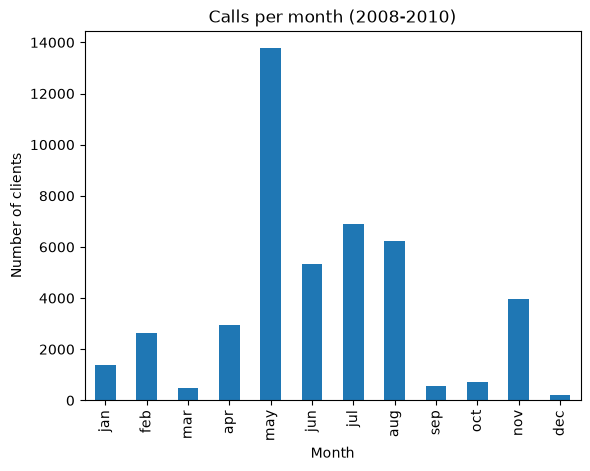

In [14]:
month_order = ["jan", "feb", "mar", "apr", "may", "jun", "jul", "aug", "sep", "oct", "nov", "dec"]
calls_per_month = clean["month"].value_counts().reindex(month_order)
print(calls_per_month)

ax = calls_per_month.plot(kind="bar", title="Calls per month (2008-2010)")
ax.set_xlabel("Month")
ax.set_ylabel("Number of clients")

job
blue-collar      9732
management       9457
technician       7597
admin.           5171
services         4154
retired          2264
self-employed    1579
entrepreneur     1487
unemployed       1303
housemaid        1240
student           938
unknown           288
Name: count, dtype: int64


Text(0.5, 0, 'Number of clients')

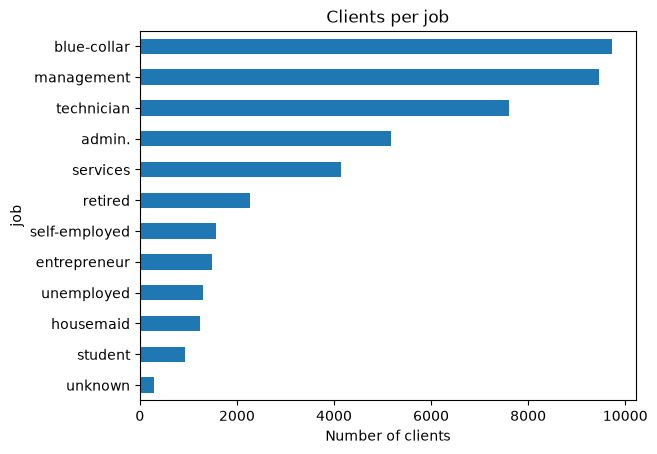

In [15]:
print(clean["job"].value_counts())

ax = clean["job"].value_counts().sort_values().plot(kind="barh", title="Clients per job")
ax.set_xlabel("Number of clients")

poutcome
unknown    36959
failure     4901
other       1839
success     1511
Name: count, dtype: int64
poutcome
unknown    81.7
failure    10.8
other       4.1
success     3.3
Name: count, dtype: float64


Text(0.5, 0, 'Number of clients')

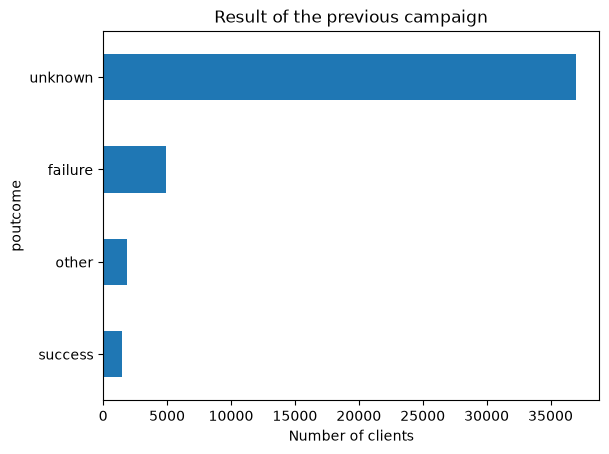

In [16]:
counts = clean["poutcome"].value_counts()
print(counts)
print((counts / len(clean) * 100).round(1))

ax = counts.sort_values().plot(kind="barh", title="Result of the previous campaign")
ax.set_xlabel("Number of clients")

default
no     44395
yes      815
Name: count, dtype: int64
default
no     98.2
yes     1.8
Name: count, dtype: float64


Text(0, 0.5, 'Number of clients')

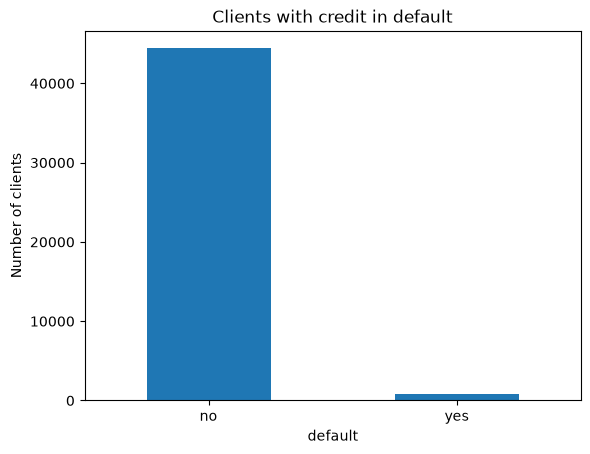

In [17]:
counts = clean["default"].value_counts()
print(counts)
print((counts / len(clean) * 100).round(1))

ax = counts.plot(kind="bar", title="Clients with credit in default")
ax.set_xticklabels(counts.index, rotation=0)
ax.set_ylabel("Number of clients")

### 3.3.2 Relations between variables and target
#### 3.3.2.1 Numeric features vs target

Clients who said "yes" and "no" have a similar median age (38 vs 39 years), but the box for the "yes" group is wider. The share of young and older clients is higher in the "yes" group. We can see this from the upper whisker, which reaches around 78 years for the "yes" group because older clients are common in this group. For the "no" group, it stops at 70 years, and older clients appear as outliers.

The relationship between age and the target variable is U-shaped. This explains why the linear correlation between age and `y` is close to zero.

        age  balance  campaign
y                             
False  39.0    417.0       2.0
True   38.0    733.0       2.0


Text(0.5, 0.98, '')

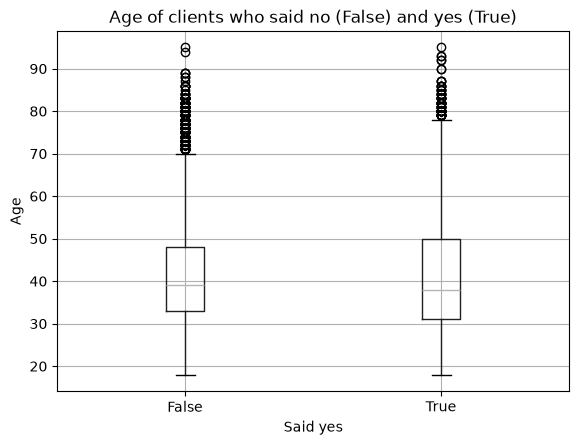

In [18]:
print(clean.groupby("y")[["age", "balance", "campaign"]].median())

ax = clean.boxplot(column="age", by="y")
ax.set_title("Age of clients who said no (False) and yes (True)")
ax.set_xlabel("Said yes")
ax.set_ylabel("Age")
plt.suptitle("")

age_band
18-25    24.0
26-30    14.5
31-40    10.2
41-50     9.1
51-60    10.1
61+      42.3
Name: y, dtype: float64


Text(0.5, 0, 'Age band')

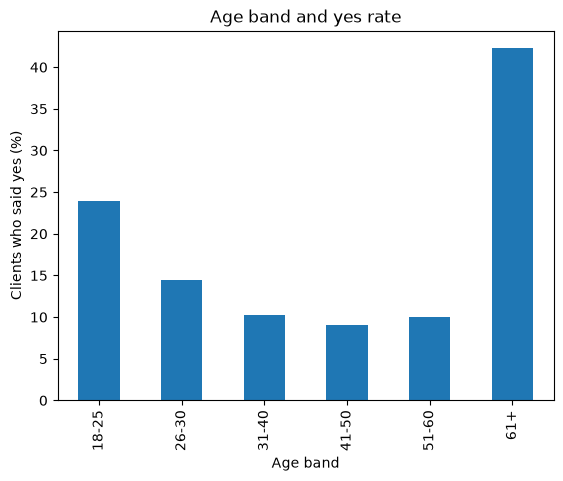

In [19]:
clean["age_band"] = pd.cut(clean["age"], bins=[17, 25, 30, 40, 50, 60, 100],
                           labels=["18-25", "26-30", "31-40", "41-50", "51-60", "61+"])
rate = clean.groupby("age_band", observed=True)["y"].mean() * 100
print(rate.round(1))

ax = rate.plot(kind="bar", title="Age band and yes rate")
ax.set_ylabel("Clients who said yes (%)")
ax.set_xlabel("Age band")

#### 3.3.2.2 ANOVA test
Here we ask whether the mean of a numeric variable is statistically different between "yes" and "no".

The p-value is the probability of seeing such a large difference if the groups were actually equal.
- p-value < 0.05: it is very unlikely to be by chance, so the difference is "statistically significant".
- p-value ≥ 0.05: the difference could be due to chance.

All the p-values are very small, which means the difference is statistically significant.
The two boxes overlap a lot: a client with a balance of 700 EUR could belong to either group. So the balance helps, but it cannot separate "yes" from "no" on its own.

We had previously observed that the more a client is called in this campaign, the lower the "yes" rate. This agrees with the ANOVA (an average of 2.1 calls for "yes" vs 2.8 for "no"). There is no cause-and-effect relationship: when a client says yes, the bank simply stops calling them, so the clients with many calls are the ones who said no.

In [20]:
for column in ["age", "balance", "campaign"]:
    yes_values = clean.loc[clean["y"], column]
    no_values = clean.loc[~clean["y"], column]
    f_stat, p_value = stats.f_oneway(yes_values, no_values)
    print(
        f"{column:10} mean yes = {yes_values.mean():8.1f} | "
        f"mean no = {no_values.mean():8.1f} | "
        f"p-value = {p_value:.2e}"
    )

age        mean yes =     41.7 | mean no =     40.8 | p-value = 8.84e-08
balance    mean yes =   1804.3 | mean no =   1303.7 | p-value = 2.54e-29
campaign   mean yes =      2.1 | mean no =      2.8 | p-value = 1.01e-54


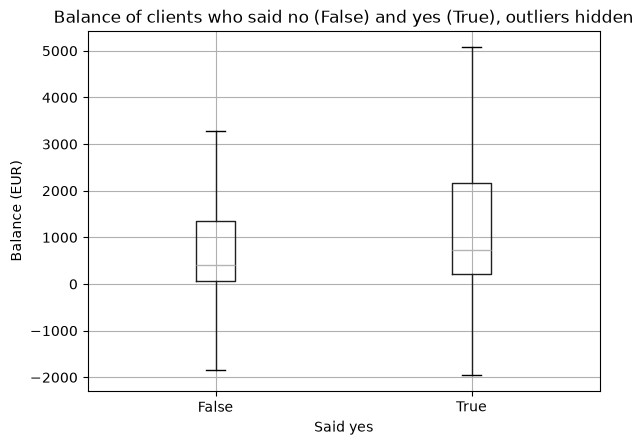

In [21]:
ax = clean.boxplot(column="balance", by="y", showfliers=False)
ax.set_title("Balance of clients who said no (False) and yes (True), outliers hidden")
ax.set_xlabel("Said yes")
ax.set_ylabel("Balance (EUR)")
plt.suptitle("")
plt.show()

#### 3.3.2.3 Categorical features vs target

Here we ask which categories have a higher or lower share of "yes" than the average (11.7%).

* `poutcome`: Clients who subscribed in the previous campaign say "yes" 64.7% of the time, which is more than 5 times the average (11.7%).
* `job`: Students and retired people say "yes" much more often than the average.
* `month`: March, September, October, and December have very high "yes" rates, while May has the lowest.

poutcome
failure    12.6
other      16.7
success    64.7
unknown     9.2
Name: y, dtype: float64
poutcome
unknown    36959
failure     4901
other       1839
success     1511
Name: count, dtype: int64


Text(0.5, 0, 'Clients who said yes (%)')

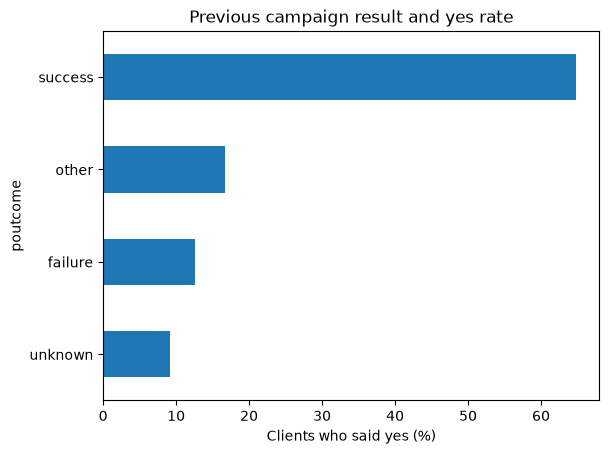

In [22]:
rate = clean.groupby("poutcome")["y"].mean() * 100
print(rate.round(1))
print(clean["poutcome"].value_counts())

ax = rate.sort_values().plot(kind="barh", title="Previous campaign result and yes rate")
ax.set_xlabel("Clients who said yes (%)")

job
admin.           12.2
blue-collar       7.3
entrepreneur      8.3
housemaid         8.8
management       13.8
retired          22.8
self-employed    11.8
services          8.9
student          28.7
technician       11.1
unemployed       15.5
unknown          11.8
Name: y, dtype: float64


Text(0.5, 0, 'Clients who said yes (%)')

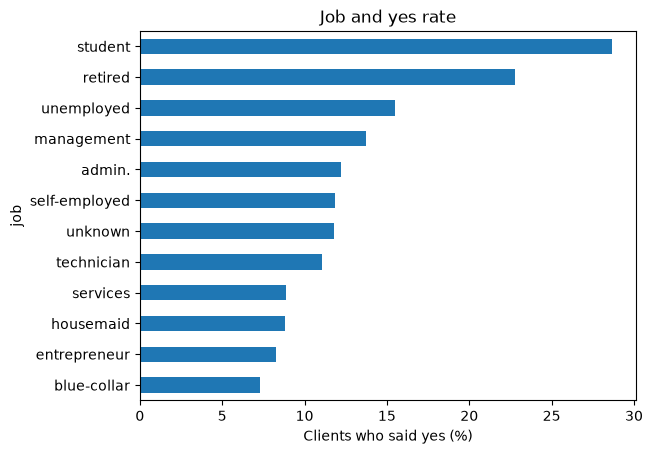

In [23]:
rate = clean.groupby("job")["y"].mean() * 100
print(rate.round(1))

ax = rate.sort_values().plot(kind="barh", title="Job and yes rate")
ax.set_xlabel("Clients who said yes (%)")

calls
1      14.6
2      11.2
3      11.2
4-5     8.6
6+      5.8
Name: y, dtype: float64
calls
1      17544
2      12504
3       5521
4-5     5286
6+      4355
Name: count, dtype: int64


Text(0, 0.5, 'Clients who said yes (%)')

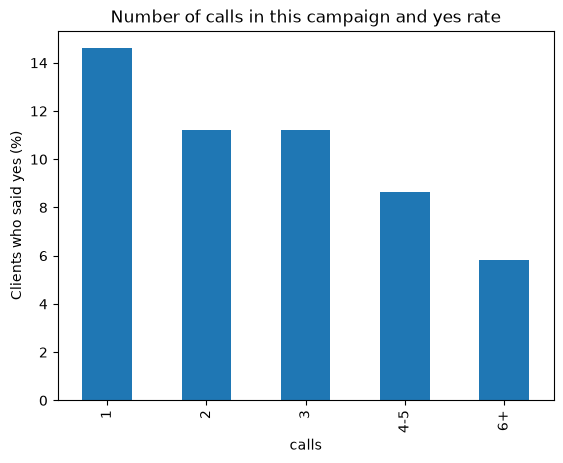

In [24]:
# Group the number of calls into bands: 1, 2, 3, 4-5, 6 or more
clean["calls"] = pd.cut(clean["campaign"], bins=[0, 1, 2, 3, 5, 100],
                        labels=["1", "2", "3", "4-5", "6+"])

rate = clean.groupby("calls")["y"].mean() * 100
print(rate.round(1))
print(clean["calls"].value_counts())

ax = rate.plot(kind="bar", title="Number of calls in this campaign and yes rate")
ax.set_ylabel("Clients who said yes (%)")

month
jan    10.1
feb    16.7
mar    52.0
apr    19.7
may     6.7
jun    10.2
jul     9.1
aug    11.0
sep    46.5
oct    43.8
nov    10.2
dec    46.7
Name: y, dtype: float64


Text(0, 0.5, 'Clients who said yes (%)')

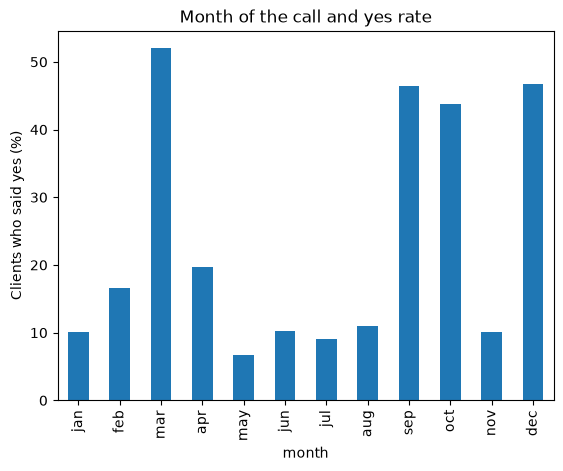

In [25]:
rate = clean.groupby("month")["y"].mean().reindex(month_order) * 100
print(rate.round(1))

ax = rate.plot(kind="bar", title="Month of the call and yes rate")
ax.set_ylabel("Clients who said yes (%)")

#### 3.3.2.4 Chi-square test

Is a categorical feature statistically associated with the target?
All features are associated with the targe.

In [26]:
for column in ["poutcome", "job", "month", "housing", "marital"]:
    table = pd.crosstab(clean[column], clean["y"])
    chi2, p_value, dof, expected = stats.chi2_contingency(table)
    print(f"{column:10} chi2 = {chi2:8.1f} | p-value = {p_value:.2e}")

poutcome   chi2 =   4391.6 | p-value = 0.00e+00
job        chi2 =    836.1 | p-value = 3.28e-172
month      chi2 =   3061.9 | p-value = 0.00e+00
housing    chi2 =    874.7 | p-value = 3.06e-192
marital    chi2 =    196.5 | p-value = 2.19e-43


### 3.3.3 Multivariate analysis and potential problems

So far we looked at one feature at a time. Now we look at two features together, to check if a relation is real or explained by another feature.

All correlations are weak (between -0.08 and 0.12 with the target, and low between the variables).
The group charts in the "Relations between variables and target" section show strong differences, so the relationships are not linear and, as a result, correlation alone would not catch them. There is no multicollinearity problem.

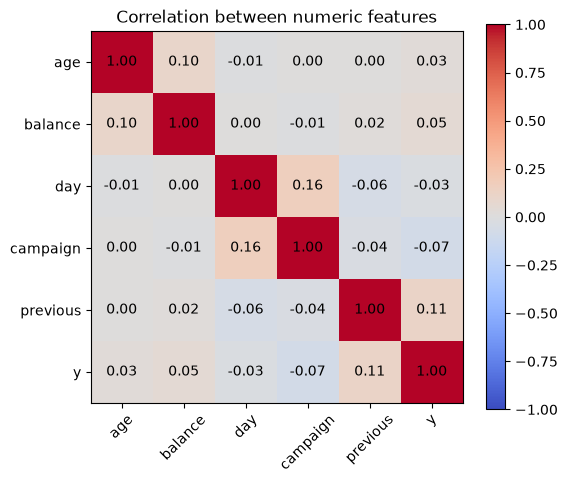

In [27]:
numbers = clean[["age", "balance", "day", "campaign", "previous", "y"]].astype(float)
corr = numbers.corr()

fig, ax = plt.subplots(figsize=(6, 5))
image = ax.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr)), corr.columns, rotation=45)
ax.set_yticks(range(len(corr)), corr.columns)
for i in range(len(corr)):
    for j in range(len(corr)):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center")
fig.colorbar(image)
ax.set_title("Correlation between numeric features")
plt.show()